# Challenge 1 – Apartment Rental Price Prediction (CAI 4105, Team 11)
**FINAL NOTEBOOK.** Complete workflow: load data → EDA → preprocessing → validation → 4 required models (+ extras) → Grid Search → feature engineering → final model → `predictions.csv`. Run top to bottom from inside `1-challenge/`.

Sections: **Part 1 – EDA & outlier investigation (Carlos)**, **Part 2 – Preprocessing, validation, modeling, tuning, final model & predictions (Abhiram)**.

# Part 1 – EDA & outlier investigation (Carlos)

#### EDA

In [1]:
import pandas as pd

df = pd.read_csv("data/challenge1_train.csv")


In [2]:
df

,ID,price,bathrooms,bedrooms,square_feet,latitude,longitude,category,has_photo,state
0,2,925,1.0,0,116,47.6160,-122.3275,housing/rent/apartment,Thumbnail,WA
1,3,2475,1.0,0,130,40.7629,-73.9885,housing/rent/apartment,Thumbnail,NY
2,5,1695,1.0,0,190,37.7599,-122.4379,housing/rent/apartment,Thumbnail,CA
3,6,1560,1.0,1,200,35.0847,-77.0609,housing/rent/apartment,Thumbnail,NC
4,7,1560,1.0,1,200,35.0960,-77.0272,housing/rent/apartment,Thumbnail,NC
...,...,...,...,...,...,...,...,...,...,...
7393,9858,8345,4.0,8,4900,43.0724,-89.4003,housing/rent/apartment,Thumbnail,WI
7394,9860,3200,5.0,6,5199,33.4072,-84.4523,housing/rent/apartment,Thumbnail,GA
7395,9861,4500,5.0,4,5407,44.8653,-93.4749,housing/rent/apartment,Thumbnail,MN
7396,9862,6900,5.0,5,5700,28.1253,-82.4468,housing/rent/apartment,Thumbnail,FL


In [3]:
df["state"].unique()

<StringArray>
['WA', 'NY', 'CA', 'NC', 'TX', 'GA', 'FL', 'MD', 'CO', 'VA', 'NM', 'IL', 'MA',
 'NJ', 'OR', 'DE', 'PA', 'AZ', 'SC', 'MN', 'TN', 'MI', 'KY', 'DC', 'AK', 'IA',
 'CT', 'WI', 'IN', 'NV', 'UT', 'OH', 'MO', 'OK', 'RI', 'NH', 'NE', 'ND', 'AL',
 'AR', 'LA', 'KS', 'ID', 'HI', 'MT', 'VT', 'SD', 'MS', 'ME', 'WV']
Length: 50, dtype: str

In [4]:
df["category"].unique()

<StringArray>
['housing/rent/apartment', 'housing/rent/home', 'housing/rent/short_term']
Length: 3, dtype: str

In [5]:
df["has_photo"].unique()

<StringArray>
['Thumbnail', 'Yes', 'No']
Length: 3, dtype: str

In [6]:
print("Number of training columns:", len(df.columns))

Number of training columns: 10


In [7]:
print(df.columns)

Index(['ID', 'price', 'bathrooms', 'bedrooms', 'square_feet', 'latitude',
       'longitude', 'category', 'has_photo', 'state'],
      dtype='str')


#### Drop price and ID

In [8]:

import pandas as pd

# Load the training dataset
train_df = df.copy()

# Separate target and predictors
y = train_df["price"]
X = train_df.drop(columns=["ID", "price"])

# Check the data
print("Training features:", X.shape)
print("Target:", y.shape)

train_df

Training features: (7398, 8)
Target: (7398,)


,ID,price,bathrooms,bedrooms,square_feet,latitude,longitude,category,has_photo,state
0,2,925,1.0,0,116,47.6160,-122.3275,housing/rent/apartment,Thumbnail,WA
1,3,2475,1.0,0,130,40.7629,-73.9885,housing/rent/apartment,Thumbnail,NY
2,5,1695,1.0,0,190,37.7599,-122.4379,housing/rent/apartment,Thumbnail,CA
3,6,1560,1.0,1,200,35.0847,-77.0609,housing/rent/apartment,Thumbnail,NC
4,7,1560,1.0,1,200,35.0960,-77.0272,housing/rent/apartment,Thumbnail,NC
...,...,...,...,...,...,...,...,...,...,...
7393,9858,8345,4.0,8,4900,43.0724,-89.4003,housing/rent/apartment,Thumbnail,WI
7394,9860,3200,5.0,6,5199,33.4072,-84.4523,housing/rent/apartment,Thumbnail,GA
7395,9861,4500,5.0,4,5407,44.8653,-93.4749,housing/rent/apartment,Thumbnail,MN
7396,9862,6900,5.0,5,5700,28.1253,-82.4468,housing/rent/apartment,Thumbnail,FL


In [9]:
print(train_df.columns)

Index(['ID', 'price', 'bathrooms', 'bedrooms', 'square_feet', 'latitude',
       'longitude', 'category', 'has_photo', 'state'],
      dtype='str')


#### investigate outliers

In [10]:

# Numerical columns and target
numeric_cols = [
    "bathrooms", "bedrooms", "square_feet",
    "latitude", "longitude", "price"
]

train_df[numeric_cols].describe()



,bathrooms,bedrooms,square_feet,latitude,longitude,price
count,7398.000000,7398.000000,7398.000000,7398.000000,7398.000000,7398.000000
mean,1.379832,1.743850,940.935253,37.647724,-94.407727,1462.805488
std,0.602894,0.936658,502.246805,5.517342,15.722082,821.583589
min,1.000000,0.000000,116.000000,21.315500,-158.022100,200.000000
25%,1.000000,1.000000,650.000000,33.604700,-98.529000,949.000000
50%,1.000000,2.000000,807.500000,38.770100,-93.651600,1273.500000
75%,2.000000,2.000000,1100.000000,41.349800,-81.643700,1695.000000
max,7.000000,9.000000,5921.000000,61.594000,-70.346100,8800.000000


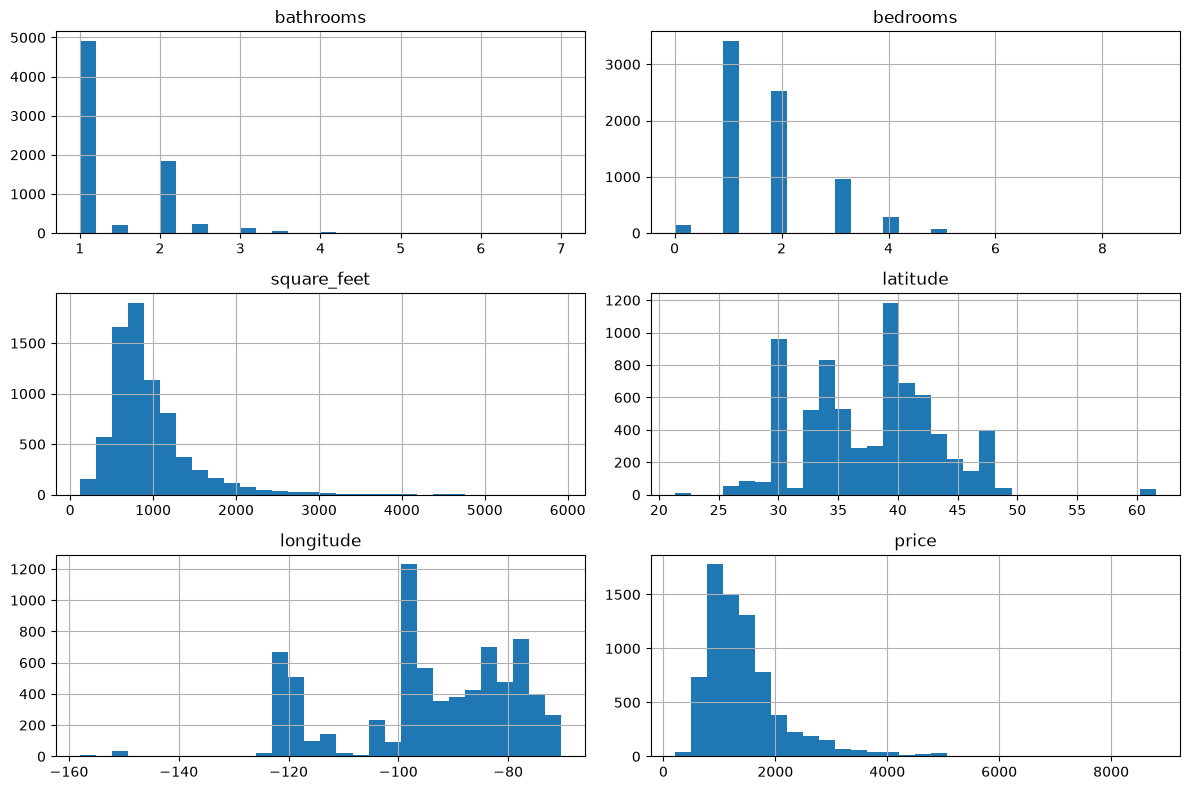

In [11]:

import matplotlib.pyplot as plt

train_df[numeric_cols].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

In [12]:

numeric_cols = [
    "bathrooms", "bedrooms", "square_feet",
    "latitude", "longitude", "price"
]

total_rows = len(train_df)

for col in numeric_cols:
    Q1 = train_df[col].quantile(0.25)
    Q3 = train_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (train_df[col] < lower_bound) |
        (train_df[col] > upper_bound)
    )

    count = outliers.sum()
    percentage = count / total_rows * 100

    print(f"\n{col}")
    print(f"Outlier count: {count}")
    print(f"Percentage of dataset: {percentage:.2f}%")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")


bathrooms
Outlier count: 48
Percentage of dataset: 0.65%
Lower bound: -0.50
Upper bound: 3.50

bedrooms
Outlier count: 370
Percentage of dataset: 5.00%
Lower bound: -0.50
Upper bound: 3.50

square_feet
Outlier count: 455
Percentage of dataset: 6.15%
Lower bound: -25.00
Upper bound: 1775.00

latitude
Outlier count: 44
Percentage of dataset: 0.59%
Lower bound: 21.99
Upper bound: 52.97

longitude
Outlier count: 44
Percentage of dataset: 0.59%
Lower bound: -123.86
Upper bound: -56.32

price
Outlier count: 443
Percentage of dataset: 5.99%
Lower bound: -170.00
Upper bound: 2814.00


##### Outlier Detection summary

I used the Interquartile Range (IQR) method with a multiplier of 1.5 to identify potential outliers in the numerical features. The largest percentages of flagged observations occurred in `square_feet` (6.15%), `price` (5.99%), and `bedrooms` (5.00%). Outliers were also identified in `bathrooms`, `latitude`, and `longitude`.

After reviewing the summary statistics, I decided to retain the observations because extreme values may represent legitimate rental listings rather than data errors. No rows were removed solely based on the IQR method.


# Part 2 – Preprocessing, validation, modeling, tuning & final predictions (Abhiram)

In [13]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import KFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error

SEED = 42
train = pd.read_csv("data/challenge1_train.csv")
test  = pd.read_csv("data/challenge1_test.csv")
print(train.shape, test.shape)
train.head()

(7398, 10) (2467, 9)


,ID,price,bathrooms,bedrooms,square_feet,latitude,longitude,category,has_photo,state
0,2,925,1.0,0,116,47.6160,-122.3275,housing/rent/apartment,Thumbnail,WA
1,3,2475,1.0,0,130,40.7629,-73.9885,housing/rent/apartment,Thumbnail,NY
2,5,1695,1.0,0,190,37.7599,-122.4379,housing/rent/apartment,Thumbnail,CA
3,6,1560,1.0,1,200,35.0847,-77.0609,housing/rent/apartment,Thumbnail,NC
4,7,1560,1.0,1,200,35.0960,-77.0272,housing/rent/apartment,Thumbnail,NC


## 1. Data exploration

In [14]:
print(train.isna().sum().sum(), "missing in train;", test.isna().sum().sum(), "in test")
print(train.drop(columns="ID").describe().T.round(2))
for c in ["category","has_photo"]: print(train[c].value_counts().to_dict())
print("states: train", train.state.nunique(), "| test-only states:", set(test.state)-set(train.state))

0 missing in train; 0 in test
              count     mean     std     min     25%      50%      75%  \
price        7398.0  1462.81  821.58  200.00  949.00  1273.50  1695.00   
bathrooms    7398.0     1.38    0.60    1.00    1.00     1.00     2.00   
bedrooms     7398.0     1.74    0.94    0.00    1.00     2.00     2.00   
square_feet  7398.0   940.94  502.25  116.00  650.00   807.50  1100.00   
latitude     7398.0    37.65    5.52   21.32   33.60    38.77    41.35   
longitude    7398.0   -94.41   15.72 -158.02  -98.53   -93.65   -81.64   

                 max  
price        8800.00  
bathrooms       7.00  
bedrooms        9.00  
square_feet  5921.00  
latitude       61.59  
longitude     -70.35  
{'housing/rent/apartment': 7395, 'housing/rent/home': 2, 'housing/rent/short_term': 1}
{'Thumbnail': 6566, 'Yes': 693, 'No': 139}
states: train 50 | test-only states: {'WY'}


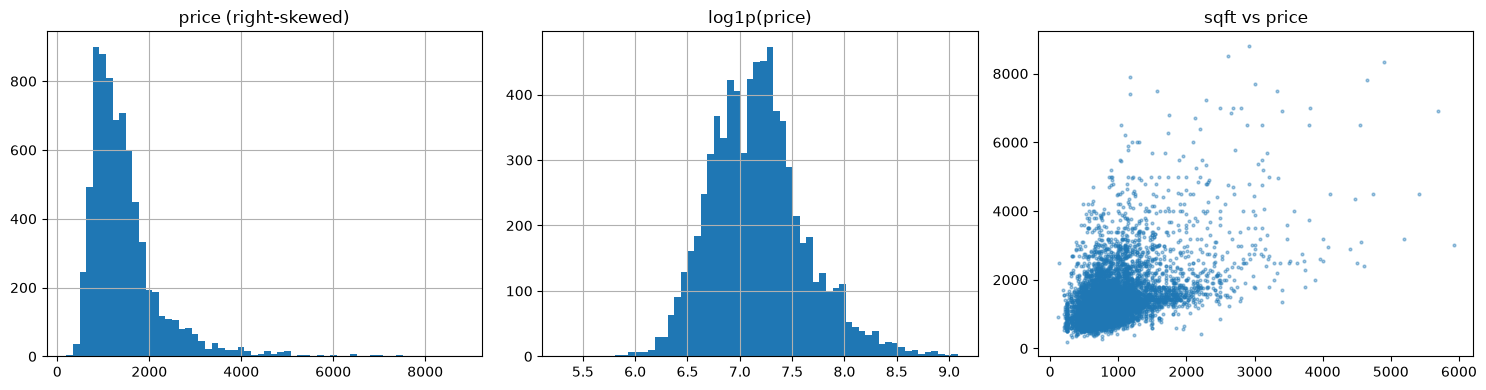

price          1.00
bathrooms      0.44
bedrooms       0.36
square_feet    0.48
latitude       0.04
longitude     -0.19
Name: price, dtype: float64
       count  median
state               
HI        10  2850.0
CA       688  2325.0
MA       119  2274.0
WV         1  2000.0
DC        62  1966.0
ME         2  1862.5
NJ       294  1811.0
WA       375  1675.0


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15,4))
train.price.hist(bins=60, ax=ax[0]); ax[0].set_title("price (right-skewed)")
np.log1p(train.price).hist(bins=60, ax=ax[1]); ax[1].set_title("log1p(price)")
ax[2].scatter(train.square_feet, train.price, s=4, alpha=.4); ax[2].set_title("sqft vs price")
plt.tight_layout(); plt.show()
print(train[["price","bathrooms","bedrooms","square_feet","latitude","longitude"]].corr()["price"].round(2))
print(train.groupby("state").price.agg(["count","median"]).sort_values("median",ascending=False).head(8))

**Findings.** No missing values (data already cleaned). Price is strongly right-skewed (log helps), and location (state / lat-lon) matters a lot.
`category` is ~constant (7395 of 7398 are `apartment`) so it carries no signal and is dropped. `ID` is dropped (not a predictor). `WY` appears only in test, so one-hot encoding uses `handle_unknown="ignore"`.

## 2. Preprocessing & validation strategy
* **Preprocessing lives inside sklearn Pipelines**, so scaling/encoding are fit only on the training folds (no leakage).
* Linear model: standardize numerics + one-hot categoricals. Tree models: no scaling needed.
* **Validation: 5-fold shuffled KFold (seed 42) on the training data only**, used for every model, every grid search and the final choice. Metric: RMSE on the original dollar scale. We report train RMSE vs CV RMSE to diagnose over/underfitting.
* Test set is never touched until the final prediction.

In [16]:
X = train.drop(columns=["ID","price","category"]); y = train["price"]
X_test = test.drop(columns=["ID","category"])
num = ["bathrooms","bedrooms","square_feet","latitude","longitude"]; cat = ["has_photo","state"]
cv = KFold(5, shuffle=True, random_state=SEED)

def prep(scale):
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", num),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])

def evaluate(name, model, X=X):
    r = cross_validate(model, X, y, cv=cv, scoring="neg_root_mean_squared_error", return_train_score=True, n_jobs=-1)
    return dict(model=name, train_RMSE=-r["train_score"].mean(), cv_RMSE=-r["test_score"].mean(), cv_std=r["test_score"].std())

## 3. Baseline: the four required models (+ extras)

In [17]:
base = {
 "Mean baseline (dummy)": None,
 "Linear Regression": Pipeline([("p",prep(True)),("m",LinearRegression())]),
 "Decision Tree":      Pipeline([("p",prep(False)),("m",DecisionTreeRegressor(random_state=SEED))]),
 "Random Forest":      Pipeline([("p",prep(False)),("m",RandomForestRegressor(n_estimators=200,random_state=SEED,n_jobs=-1))]),
 "Gradient Boosting":  Pipeline([("p",prep(False)),("m",GradientBoostingRegressor(random_state=SEED))]),
 "Hist Gradient Boosting (extra)": Pipeline([("p",prep(False)),("m",HistGradientBoostingRegressor(random_state=SEED))]),
}
from sklearn.dummy import DummyRegressor
base["Mean baseline (dummy)"] = DummyRegressor()
res = pd.DataFrame([evaluate(k,v) for k,v in base.items()]).round(1)
res

,model,train_RMSE,cv_RMSE,cv_std
0,Mean baseline (dummy),821.4,820.7,41.8
1,Linear Regression,521.0,526.8,25.3
2,Decision Tree,40.7,556.0,52.5
3,Random Forest,161.2,423.7,33.3
4,Gradient Boosting,406.7,461.4,27.7
5,Hist Gradient Boosting (extra),317.6,409.1,26.1


Reading the table: the default Decision Tree has a tiny train RMSE vs a much larger CV RMSE → **overfits**. Linear Regression has similar train/CV error but a high level → **underfits** (price vs sqft/location is non-linear). Ensembles do best.

## 4. Improvement: feature engineering + log target + Grid Search
Feature engineering (all inside the pipeline, row-wise so no leakage): `log_sqft`, `sqft_per_bedroom`, `total_rooms`, `bath_per_bed`.
Target transform: train on `log1p(price)` and invert with `expm1` (`TransformedTargetRegressor`), RMSE still measured in dollars.

In [18]:
def add_feats(d):
    d = d.copy()
    d["log_sqft"] = np.log1p(d.square_feet)
    d["total_rooms"] = d.bedrooms + d.bathrooms
    d["sqft_per_bed"] = d.square_feet / (d.bedrooms + 1)
    d["bath_per_bed"] = d.bathrooms / (d.bedrooms + 1)
    return d
FE = FunctionTransformer(add_feats)
num2 = num + ["log_sqft","total_rooms","sqft_per_bed","bath_per_bed"]
def prep2(scale):
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", num2),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
def pipe(model, scale=False, logy=True):
    p = Pipeline([("fe",FE),("p",prep2(scale)),("m",model)])
    return TransformedTargetRegressor(p, func=np.log1p, inverse_func=np.expm1) if logy else p

fe_check = pd.DataFrame([
  evaluate("RF raw target",      pipe(RandomForestRegressor(200,random_state=SEED,n_jobs=-1), logy=False)),
  evaluate("RF + FE + log y",    pipe(RandomForestRegressor(200,random_state=SEED,n_jobs=-1))),
  evaluate("GB raw target",      pipe(GradientBoostingRegressor(random_state=SEED), logy=False)),
  evaluate("GB + FE + log y",    pipe(GradientBoostingRegressor(random_state=SEED))),
  evaluate("LinReg + FE + log y",pipe(LinearRegression(), scale=True)),
]).round(1); fe_check

,model,train_RMSE,cv_RMSE,cv_std
0,RF raw target,163.0,429.3,33.4
1,RF + FE + log y,177.3,421.2,35.4
2,GB raw target,399.7,457.1,26.1
3,GB + FE + log y,430.5,468.6,26.8
4,LinReg + FE + log y,506.3,512.2,29.6


In [19]:
grids = {
 "Ridge": (pipe(Ridge(), scale=True), {"regressor__m__alpha":[0.1,1,10,100]}),
 "Decision Tree": (pipe(DecisionTreeRegressor(random_state=SEED)),
     {"regressor__m__max_depth":[4,6,8,10,14],"regressor__m__min_samples_leaf":[1,5,10,20]}),
 "Random Forest": (pipe(RandomForestRegressor(n_estimators=200,random_state=SEED,n_jobs=-1)),
     {"regressor__m__max_depth":[None,20],"regressor__m__min_samples_leaf":[1,3],"regressor__m__max_features":[0.5,1.0]}),
 "Gradient Boosting": (pipe(GradientBoostingRegressor(random_state=SEED)),
     {"regressor__m__n_estimators":[300,600],"regressor__m__learning_rate":[0.03,0.08],"regressor__m__max_depth":[3,5],"regressor__m__subsample":[0.8]}),
 "Hist Gradient Boosting": (pipe(HistGradientBoostingRegressor(random_state=SEED)),
     {"regressor__m__learning_rate":[0.03,0.06,0.1],"regressor__m__max_iter":[300,600],"regressor__m__max_leaf_nodes":[15,31,63],"regressor__m__l2_regularization":[0,1]}),
}
best, rows = {}, []
for name,(est,g) in grids.items():
    gs = GridSearchCV(est, g, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1, return_train_score=True).fit(X,y)
    best[name]=gs.best_estimator_; i=gs.best_index_
    rows.append(dict(model=name, train_RMSE=-gs.cv_results_["mean_train_score"][i], cv_RMSE=-gs.best_score_, cv_std=gs.cv_results_["std_test_score"][i], best_params={k.split("__")[-1]:v for k,v in gs.best_params_.items()}))
tuned = pd.DataFrame(rows).sort_values("cv_RMSE"); tuned.round(1)

,model,train_RMSE,cv_RMSE,cv_std,best_params
3,Gradient Boosting,190.6,389.9,27.9,"{'learning_rate': 0.08, 'max_depth': 5, 'n_est..."
4,Hist Gradient Boosting,262.2,396.4,25.2,"{'l2_regularization': 0, 'learning_rate': 0.1,..."
2,Random Forest,189.4,421.0,35.9,"{'max_depth': 20, 'max_features': 1.0, 'min_sa..."
1,Decision Tree,345.4,487.3,25.4,"{'max_depth': 14, 'min_samples_leaf': 5}"
0,Ridge,506.5,512.3,29.7,{'alpha': 0.1}


## 5. Final comparison & model selection

In [20]:
summary = pd.concat([res.assign(stage="baseline"), tuned.drop(columns="best_params").round(1).assign(stage="tuned (FE+log y+GridSearch)")]).sort_values("cv_RMSE")
summary[["stage","model","train_RMSE","cv_RMSE","cv_std"]].reset_index(drop=True)

,stage,model,train_RMSE,cv_RMSE,cv_std
0,tuned (FE+log y+GridSearch),Gradient Boosting,190.6,389.9,27.9
1,tuned (FE+log y+GridSearch),Hist Gradient Boosting,262.2,396.4,25.2
2,baseline,Hist Gradient Boosting (extra),317.6,409.1,26.1
3,tuned (FE+log y+GridSearch),Random Forest,189.4,421.0,35.9
4,baseline,Random Forest,161.2,423.7,33.3
5,baseline,Gradient Boosting,406.7,461.4,27.7
6,tuned (FE+log y+GridSearch),Decision Tree,345.4,487.3,25.4
7,tuned (FE+log y+GridSearch),Ridge,506.5,512.3,29.7
8,baseline,Linear Regression,521.0,526.8,25.3
9,baseline,Decision Tree,40.7,556.0,52.5


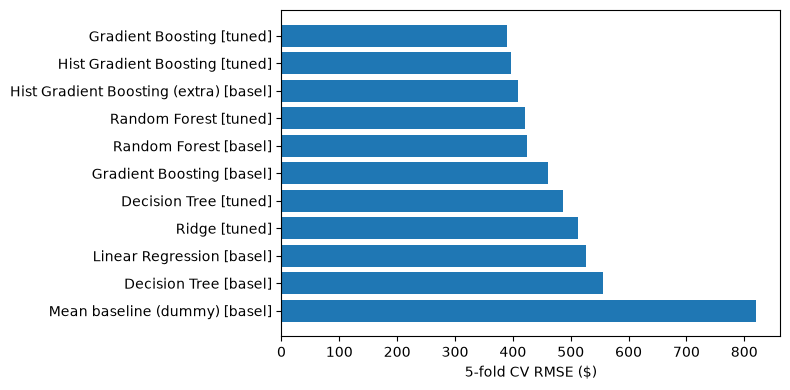

In [21]:
plt.figure(figsize=(8,4)); s=summary.sort_values("cv_RMSE",ascending=False)
plt.barh(s.model+" ["+s.stage.str[:5]+"]", s.cv_RMSE); plt.xlabel("5-fold CV RMSE ($)"); plt.tight_layout(); plt.show()

In [22]:
FINAL_NAME = tuned.iloc[0].model
final = best[FINAL_NAME]
print("Final model:", FINAL_NAME, "| CV RMSE =", round(tuned.iloc[0].cv_RMSE,1))
# Quick interpretability check: permutation importance on a held-out fold
from sklearn.inspection import permutation_importance
tr, va = next(iter(cv.split(X)))
m = __import__("sklearn").base.clone(final).fit(X.iloc[tr], y.iloc[tr])
pi = permutation_importance(m, X.iloc[va], y.iloc[va], scoring="neg_root_mean_squared_error", n_repeats=5, random_state=SEED)
pd.Series(pi.importances_mean, X.columns).sort_values(ascending=False).round(1)

Final model: Gradient Boosting | CV RMSE = 389.9


longitude      342.8
square_feet    254.7
latitude       225.4
state          156.7
bathrooms       58.1
bedrooms        21.2
has_photo        1.6
dtype: float64

### Justification
* **Validation performance:** see table, the tuned boosted/ensemble models give the lowest CV RMSE; linear regression and a single tree are clearly worse.
* **Over/underfitting:** linear models underfit (high train *and* CV error); the untuned tree overfits (tiny train, large CV error); regularized/tuned ensembles keep the train–CV gap moderate.
* **Complexity / compute / interpretability:** the chosen model is a gradient-boosted tree ensemble, more complex and less interpretable than linear regression, but it trains in seconds and the permutation importance above shows sensible drivers (size, location, bedrooms/bathrooms). The gain in RMSE justifies the trade-off.

## 6. Train on all training data & generate predictions

In [23]:
final.fit(X, y)
pred = final.predict(X_test)
out = pd.DataFrame({"ID": test.ID, "price": np.round(pred, 2)})
assert len(out)==len(test)==2467 and out.ID.is_unique and out.price.notna().all()
out.to_csv("predictions.csv", index=False)
print(out.price.describe().round(1)); out.head()

count    2467.0
mean     1445.6
std       759.8
min       435.1
25%       981.9
50%      1236.8
75%      1637.2
max      8454.6
Name: price, dtype: float64


,ID,price
0,1,1447.80
1,4,1661.81
2,9,919.69
3,11,850.56
4,13,637.70
